


**Why are we resorting to data-driven ROMs here? What is stopping us from using plain POD-Galerkin?**

The Lamé coefficients $\lambda$ and $\eta$ depend on $\delta$ through a step function in $y$:

$$\lambda(x,y) = \eta(x,y) = \begin{cases} 10 & y \geq \delta \\ 50 & y < \delta \end{cases}$$

This makes the parametrization **non-affine**. To see why, recall that affine decomposition requires:

$$A(\mu) = \sum_{q} \theta_q(\mu)\, A_q$$

where $\theta_q(\mu)$ are **parameter-dependent scalars** and $A_q$ are **parameter-independent
matrices** assembled once offline. This separation is the key to the POD-Galerkin speedup:
the expensive FEM assembly happens once offline, and online you only perform cheap scalar
multiplications and additions of small $N \times N$ reduced matrices.

For this to work, the parameter must appear **only as a scalar multiplier** in front of a
fixed integration domain. Here instead, $\delta$ controls **where the interface between the
two layers sits** — it lives inside the integration domain itself:

$$A(\mu) = 10 \cdot \underbrace{\int_{y \geq \delta} [\ldots]\, d\Omega}_{A_1(\delta)\ \neq\ \text{const}}
         + 50 \cdot \underbrace{\int_{y < \delta} [\ldots]\, d\Omega}_{A_2(\delta)\ \neq\ \text{const}}$$

The matrices $A_1(\delta)$ and $A_2(\delta)$ **change with every new $\delta$** —  as the limits of the integral will change with the value of $\delta$ so , they cannot
be precomputed offline. As a result, POD-Galerkin would still require **reassembling the full
FOM stiffness matrix** for each new $(\delta, m)$, defeating the purpose of the ROM since
no computational speedup is achieved online.

**This is why we resort to a data-driven ROM**, which bypasses the FEM assembly entirely
by learning the parameter-to-solution map directly from data.

---

**Why did we pick POD-NN over DL-ROM?**

1. **Rapid decay of the singular values:** only $N = 30$ modes are sufficient to represent the system, capturing $\approx 99\%$ of the total energy. This indicates that the solution manifold is low-dimensional and POD already provides a very good linear compression $\rightarrow$ the nonlinear encoder of DL-ROM is not needed.

2. **Limited training data:** we only have 75 training trajectories. DL-ROM must learn both the compression and the dynamics from data, which is harder with few samples. POD-NN separates the two tasks: POD handles the compression (mathematically, no training required), while the neural network only learns the map $\mu \mapsto \mathbf{c}(\mu)$ $\rightarrow$ simpler and more data-efficient.

3. We also tested DL-ROM but it gave higher test error with longer training times $\rightarrow$ POD-NN offered a better accuracy/cost tradeoff.

---

**How did we choose the latent dimension $N = 30$?**

By looking at the decay of the singular values and the cumulative energy captured:
- $N = 30$ modes capture $\approx 99\%$ of the total energy $\sum_i \sigma_i^2$.
- After mode 30, the singular values are already small and flat $\rightarrow$ adding more modes gives negligible improvement.
- The POD reconstruction error on the training set is already well below the target threshold $\rightarrow$ $N = 30$ is sufficient.

In [ ]:
try:
     from dlroms import*
except:
     !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
     from dlroms import*
import numpy as np
import matplotlib.pyplot as plt
import gdown
clc()

## Ex 3 - **Sidewalk degradation** (Linear elasticity)

### Mesh construction and data download

In [ ]:
mesh = fe.unitsquaremesh(40, 40)
Vh = fe.space(mesh, 'CG', 1, vector_valued = True)
clc()

gdown.download(id = "1jMzgW3fe0A1BRiX1O4jH0T7GGUqnqVar", output = "sidewalk.npz")
clc()

data = np.load("sidewalk.npz")


In [ ]:
mu, u = data['mu'], data['u']

mu.shape, u.shape

((100, 2), (100, 51, 3362))

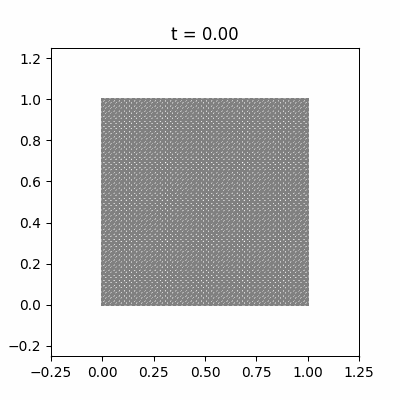

In [ ]:
# Visualization of the first simulation in the dataset
fe.animate(u[0], Vh, warp = True, axis = [-0.25, 1.25, -0.25, 1.25], T = 5, dt = 0.1)

### Auxiliary tools

In [ ]:
ns, nt, nh = u.shape
ntrain =(int) (ns * 0.75)*(nt)

In [ ]:
mu, u = dv.tensor(data['mu']), dv.tensor(data['u'])
p = mu.shape[-1]
print("Trajectories:\t%d." % ns)
print("Timesteps:\t%d." % nt)
print("FOM dimension:\t%d." % nh)
print("Parameters:\t%d." % p)


Trajectories:	100.
Timesteps:	51.
FOM dimension:	3362.
Parameters:	2.


In [ ]:
## building the mut matrix
mut = dv.zeros(ns, nt, p+1)  # mut(100 , 51 , 3)
times = dv.tensor(np.linspace(0, 1, nt))
for i in range(ns):
    mut[i,:,:2] = mu[i]
    mut[i,:, 2] = times
## reshaping mut to (5100 , 3)
mut = mut.reshape(-1, p+1)
## generating U (5100 , 3362)
U = u.reshape(-1, nh)

In [ ]:
l2 = L2(Vh)
l2.cuda()
clc()
def error(utrue, upred):
    return (l2(utrue-upred).reshape(-1, nt).sum(axis = -1)/l2(utrue).reshape(-1, nt).sum(axis = -1)).mean()
def error_pod(ctrue, cpred):
    return (euclidean(ctrue - cpred).sum() / euclidean(ctrue).sum()).mean()
def error_auto_encoder(utrue, upred):
    return (l2(utrue - upred).sum() / l2(utrue).sum()).mean()


## Training

1st staring with te SVD


In [ ]:
from scipy.linalg import svd

In [ ]:
X , s , yt = svd(U[:ntrain].T.cpu().numpy() , full_matrices= False)

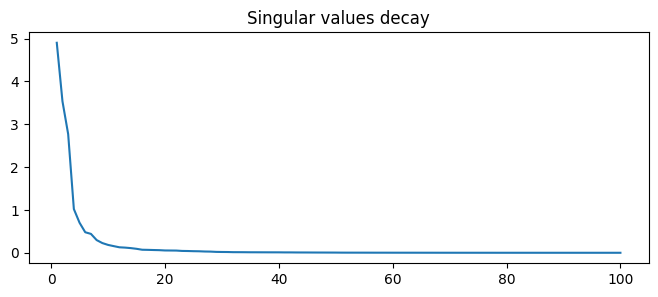

In [ ]:
plt.figure(figsize = (8, 3))
plt.plot(1+np.arange(100), s[1:101])
plt.title("Singular values decay")
plt.show()

In [ ]:
N = 30

In [ ]:

sused = s[:N]
captured = 0
total = 0
for i in range(len(sused)):
  captured += s[i]**2
for i in range(len(s)):
  total += s[i]**2
print(captured * 100 / total , "%")

99.99998 %


## POD-NN

In [ ]:
V = dv.tensor(X[: , :N])
print("POD MRE: %s" % num2p(error(U[:ntrain], U[:ntrain] @ V @ V.T)))

POD MRE: 0.09%


In [ ]:
V.shape , U.shape

(torch.Size([3362, 30]), torch.Size([5100, 3362]))

In [ ]:
c = U @ V
c.shape

torch.Size([5100, 30])

In [ ]:
from torch.optim import Adam
from dlroms.dnns import Fourier

In [ ]:
fmodes = 30

phi_POD_NN = Fourier(fmodes, which=[-1]) + Dense(p+1+2*fmodes, 256, gelu) +  Dense(256, 512, gelu) + Dense(512, 256, gelu) + Dense(256,  N, activation=None)

model_POD_NN = DFNN(phi_POD_NN)
model_POD_NN.He()
model_POD_NN.cuda()

In [ ]:
# Phase 1
model_POD_NN.train(mut, c, ntrain=ntrain, error=error_pod, loss = mse(euclidean), epochs=1500,optim=Adam, lr=1e-3, batchsize=128, notation='%')
model_POD_NN.freeze()

		Train	Test
Epoch 1500:	3.14%	3.08%.

>> ETA: 0.12s.


Training complete. Elapsed time: 3 minutes 3.77 seconds.


(0.0, 0.5)

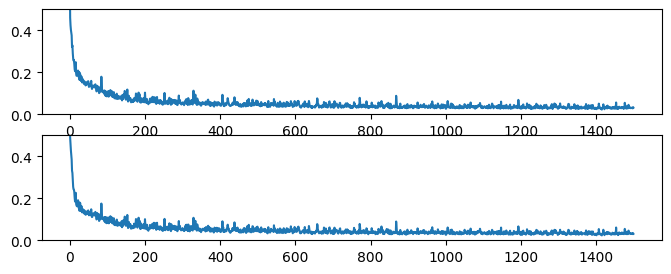

In [ ]:
plt.figure(figsize = (8, 3))

plt.subplot(2 , 1 , 1)
plt.plot(model_POD_NN.errors['Train'])
plt.ylim([0.0 , 0.5])
plt.subplot(2 , 1 , 2)
plt.plot(model_POD_NN.errors['Test'])
plt.ylim([0.0 , 0.5])

In [ ]:
# Phase 2
model_POD_NN.unfreeze()
model_POD_NN.train(mut, c, ntrain=ntrain, error=error_pod, loss = mse(euclidean), epochs=500,optim=Adam, lr=1e-4, batchsize=128, notation='%')
model_POD_NN.freeze()

		Train	Test
Epoch 500:	1.89%	2.12%.

>> ETA: 0.12s.


Training complete. Elapsed time: 59.60 seconds.


(0.015, 0.03)

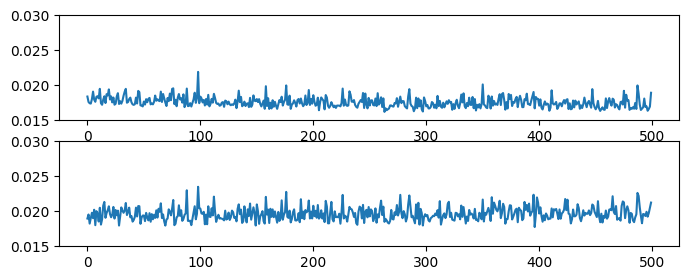

In [ ]:
plt.figure(figsize = (8, 3))

plt.subplot(2 , 1 , 1)
plt.plot(model_POD_NN.errors['Train'])
plt.ylim([0.015 , 0.03])
plt.subplot(2 , 1 , 2)
plt.plot(model_POD_NN.errors['Test'])
plt.ylim([0.015 , 0.03])

In [ ]:
# Phase 3
model_POD_NN.unfreeze()
model_POD_NN.train(mut, c, ntrain=ntrain, error=error_pod, loss = mse(euclidean), epochs=500,optim=Adam, lr=1e-5, batchsize=128, notation='%')
model_POD_NN.freeze()

		Train	Test
Epoch 500:	1.55%	1.84%.

>> ETA: 0.13s.


Training complete. Elapsed time: 1 minutes 5.34 seconds.


(0.015, 0.03)

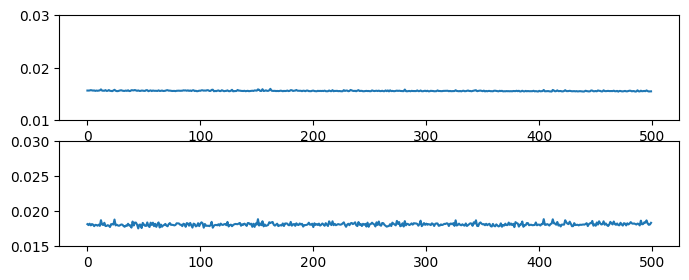

In [ ]:
plt.figure(figsize = (8, 3))

plt.subplot(2 , 1 , 1)
plt.plot(model_POD_NN.errors['Train'])
plt.ylim([0.01 , 0.03])
plt.subplot(2 , 1 , 2)
plt.plot(model_POD_NN.errors['Test'])
plt.ylim([0.015 , 0.03])

In [ ]:
# reshape back to trajectories first
u_test   = U[ntrain:].reshape(-1, nt, nh)
mut_test = mut[ntrain:].reshape(-1, nt, p+1)
uROM = model_POD_NN(mut[ntrain:]) @ V.T
print("Average relative error of POD-NN: %s." % num2p(error(U[ntrain:], uROM)))

Average relative error of POD-NN: 1.88%.


In [ ]:
model_POD_NN.save("pod_nn.npz")                          # the network weights
np.save("pod_basis.npy", V.cpu().numpy())         # the POD basis

## DL-ROM

In [ ]:
latent = 2 * p + 1

encoder = Dense(nh, 256, gelu) + Dense(256, 64, gelu) + Dense(64, latent, gelu)
decoder = Dense(latent, 64, gelu) + Dense(64, 256, gelu) + Dense(256, 512, gelu) + Dense(512, 1024, gelu) + Dense(1024, nh)

autoencoder = DFNN(encoder + decoder)
autoencoder.He()
autoencoder.cuda()

autoencoder.train(U, U, ntrain=ntrain, epochs=1500,
                  batchsize=128,
                  loss=mse(l2),
                  error=error_auto_encoder,
                  optim=Adam,
                  lr=1e-3,
                  notation='%')

autoencoder.freeze()

		Train	Test
Epoch 1500:	1.70%	1.78%.

>> ETA: 0.19s.


Training complete. Elapsed time: 4 minutes 44.76 seconds.


(0.0, 0.5)

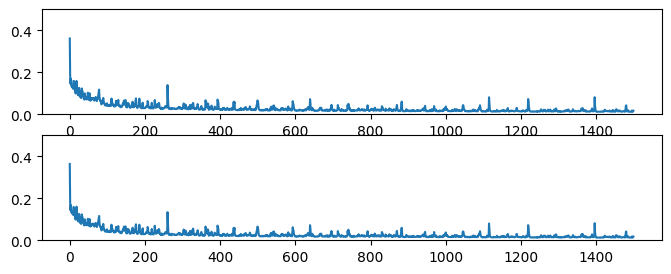

In [ ]:
plt.figure(figsize = (8, 3))

plt.subplot(2 , 1 , 1)
plt.plot(autoencoder.errors['Train'])
plt.ylim([0.0 , 0.5])
plt.subplot(2 , 1 , 2)
plt.plot(autoencoder.errors['Test'])
plt.ylim([0.0 , 0.5])

In [ ]:
autoencoder.unfreeze()
autoencoder.train(U, U, ntrain=ntrain, epochs=500,
                  batchsize=128,
                  loss=mse(l2),
                  error=error_auto_encoder,
                  optim=Adam,
                  lr=1e-4,
                  notation='%')

autoencoder.freeze()

		Train	Test
Epoch 500:	1.00%	1.11%.

>> ETA: 0.19s.


Training complete. Elapsed time: 1 minutes 32.93 seconds.


(0.0, 0.1)

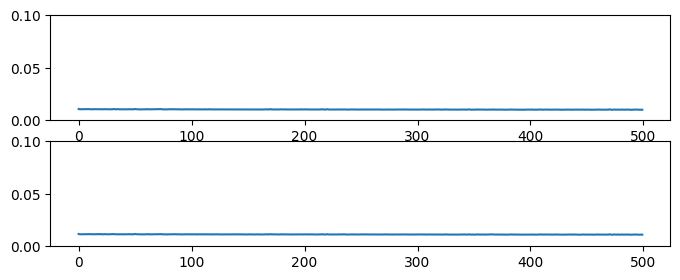

In [ ]:
plt.figure(figsize = (8, 3))

plt.subplot(2 , 1 , 1)
plt.plot(autoencoder.errors['Train'])
plt.ylim([0.0 , 0.1])
plt.subplot(2 , 1 , 2)
plt.plot(autoencoder.errors['Test'])
plt.ylim([0.0 , 0.1])

In [ ]:
nu = encoder(U)

from dlroms.dnns import Fourier
fmodes = 30
phi = DFNN(Fourier(fmodes, which=[-1]) + Dense(p+1+2*fmodes, 500, gelu) + Dense(500, latent, activation = None))

phi.He()
phi.cuda()
phi.train(mut, nu, ntrain=ntrain, epochs=1500,
          batchsize=128,
          loss=mse(euclidean),
          error=mre(euclidean),
          optim=Adam,
          lr=1e-3,
          notation='%')
phi.freeze()

		Train	Test
Epoch 1500:	10.50%	10.24%.

>> ETA: 0.11s.


Training complete. Elapsed time: 2 minutes 43.81 seconds.


(0.0, 0.5)

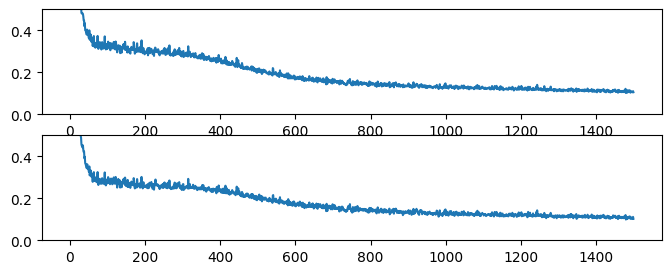

In [ ]:
plt.figure(figsize = (8, 3))

plt.subplot(2 , 1 , 1)
plt.plot(phi.errors['Train'])
plt.ylim([0.0 , 0.5])
plt.subplot(2 , 1 , 2)
plt.plot(phi.errors['Test'])
plt.ylim([0.0 , 0.5])

In [ ]:
phi.unfreeze()
phi.train(mut, nu, ntrain=ntrain, epochs=50,
                  batchsize=128,
                  loss=mse(euclidean),
                  error=mre(euclidean),
                  optim=Adam,
                  lr=1e-4,
                  notation='%')

phi.freeze()

		Train	Test
Epoch 50:	9.57%	9.58%.

>> ETA: 0.10s.


Training complete. Elapsed time: 4.95 seconds.


(0.0, 0.5)

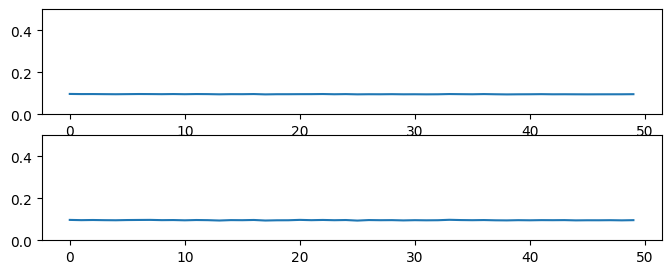

In [ ]:
plt.figure(figsize = (8, 3))

plt.subplot(2 , 1 , 1)
plt.plot(phi.errors['Train'])
plt.ylim([0.0 , 0.5])
plt.subplot(2 , 1 , 2)
plt.plot(phi.errors['Test'])
plt.ylim([0.0 , 0.5])

In [ ]:
dlrom = lambda mt: decoder(phi(mt))
print("model MRE: %s" % num2p(error(U[ntrain:], dlrom(mut[ntrain:]))))

model MRE: 3.91%


# Task 2

In [ ]:
fmodes = 30
phi_POD_NN = (
    Fourier(fmodes, which=[-1])
    + Dense(p+1+2*fmodes, 256, gelu)
    + Dense(256, 512, gelu)
    + Dense(512, 256, gelu)
    + Dense(256, N, activation=None)
)
model_POD_NN = DFNN(phi_POD_NN)
model_POD_NN.load("pod_nn.npz")
model_POD_NN.cuda()
model_POD_NN.freeze()

# Load the POD basis
V = dv.tensor(np.load("pod_basis.npy"))

In [ ]:
(U[ntrain: ] - (U[ntrain:]@V)@V.T ).pow(2).sum() # | |u - V VT ul |^2

tensor(0.0016, device='cuda:0')

In [ ]:
(U[ntrain: ] @ V - model_POD_NN(mut[ntrain:])).pow(2).sum()

tensor(0.5012, device='cuda:0')

In [ ]:
(U[ntrain: ] - model_POD_NN(mut[ntrain:]) @ V.T).pow(2).sum()

tensor(0.5027, device='cuda:0')

In [ ]:
uROM = model_POD_NN(mut[ntrain:]) @ V.T
print("POD-NN MRE: %s." % num2p(error(U[ntrain:], uROM)))

POD-NN MRE: 1.91%.


In [ ]:
from time import perf_counter

# Reshape mut to (n_samples, nt, p+1) and pick test sample index 1
mut_test = mut[ntrain:].reshape(-1, nt, p+1)
mu0t = mut_test[1]  # shape (nt, p+1) — full trajectory

t0 = perf_counter()
uROM = model_POD_NN(mu0t) @ V.T   # shape (nt, nh)
t1 = perf_counter()

print("POD-NN simulation time: %.3fs." % (t1-t0))
ratio =int(8 / (t1-t0))
print("POD-NN solver is faster than the FOM solver by: %d." % (ratio))

POD-NN simulation time: 0.004s.
POD-NN solver is faster than the FOM solver by: 1878.


In [ ]:
uROM.shape

torch.Size([51, 3362])

# Q function

In [ ]:
indexes = 1-fe.dofs(Vh)[:, 1]<1e-12   # indexes of the dofs located at the top edge
tindex = np.arange(0, 51, 10)         # indexes of the times t_1, ..., t_q

def Q(u):
  """Given a space-time solution u, returns [Q(u,t_1), ..., Q(u, t_q)].
  If multiple solutions are passed, the output is computed batchwise.

  Works both on numpy arrays and torch tensors."""

  U = u.reshape(-1, nt, nh)[:, :, indexes]
  vals = U.reshape(-1, nt, np.sum(indexes)//2, 2)[:, :, :, 1].mean(axis = -1)[:, tindex]
  return vals if len(U)>1 else vals[0]

# Test my model

In [ ]:
uROM = model_POD_NN(mut[ntrain:]) @ V.T   # shape (nt, nh)
uROM = uROM.reshape(25, nt,nh)
uROM[0].shape

torch.Size([51, 3362])

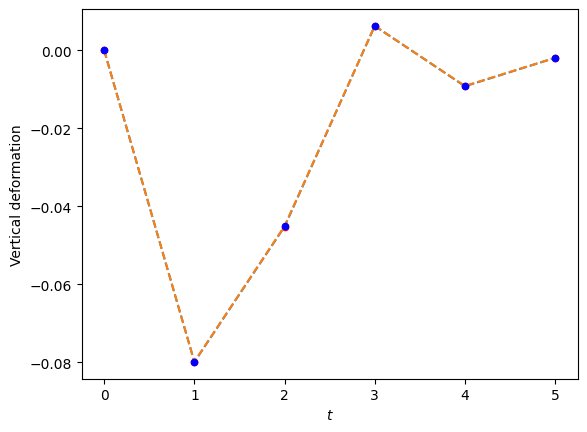

In [ ]:
# Usage example
top_vertical_deformation = Q(u[77]).cpu().numpy()   # convert output
top_vertical_deformation_ROM =Q(uROM[2]) .cpu().numpy()   # convert output
times = np.linspace(0, 5, nt)

plt.plot(times[tindex], top_vertical_deformation, '--')
plt.plot(times[tindex], top_vertical_deformation, '.', color = 'red', markersize = 9)
plt.plot(times[tindex], top_vertical_deformation_ROM, '--')
plt.plot(times[tindex], top_vertical_deformation_ROM, '.', color = 'blue', markersize = 9)
plt.xlabel("$t$")
plt.ylabel("Vertical deformation")
None

# task3

In [ ]:
# Measurements available for Task (iii)
gdown.download(id = "1H51m5HL1RC0PDxnrM-q6YGjJjfbM6cC5", output = "surface_measurements.npy")
clc()

measurements = np.load("surface_measurements.npy")
measurements

array([ 0.01079223, -0.10217915, -0.07301079,  0.00097444, -0.00993845,
        0.00946097])

In [ ]:
# ── 1. Parameter grid ──────────────────────────────────────────────────────
n_grid      = 40
delta_range = np.linspace(0.5, 0.9, n_grid)   # δ range from problem statement
m_range     = np.linspace(0.5, 1.5, n_grid)   # m range from problem statement
times_np    = np.linspace(0, 1, nt)
mismatch_grid = np.zeros((n_grid , n_grid))
m_opt = 0
delta_opt = 0
mismatch = 1
delta_counter = 0
relative_mismatch = 0
# ── 2. Sweep over all (δ, m) pairs ────────────────────────────────────────
for  delta in  (delta_range):
    m_counter = 0
    for m in (m_range):
        # Build (μ, t) input for the full trajectory
        mu0t = dv.zeros(nt, p + 1)
        mu0t[:, 0] = float(delta)
        mu0t[:, 1] = float(m)
        mu0t[:, 2] = dv.tensor(times_np)
        uROM   = model_POD_NN(mu0t) @ V.T      # (nt, nh)
        Q_pred = Q(uROM).cpu().numpy()          # (6,) — predicted camera values
        test = np.linalg.norm(Q_pred - measurements)
        mismatch_grid[delta_counter , m_counter] = test
        if test < mismatch:
          mismatch = test
          m_opt = m
          delta_opt = delta
          relative_mismatch = mismatch / np.linalg.norm(measurements)
        m_counter += 1



    delta_counter += 1




In [ ]:
mismatch , m_opt , delta_opt , relative_mismatch


(np.float64(0.021981761919704686),
 np.float64(1.3205128205128205),
 np.float64(0.7769230769230769),
 np.float64(0.17336518975633894))

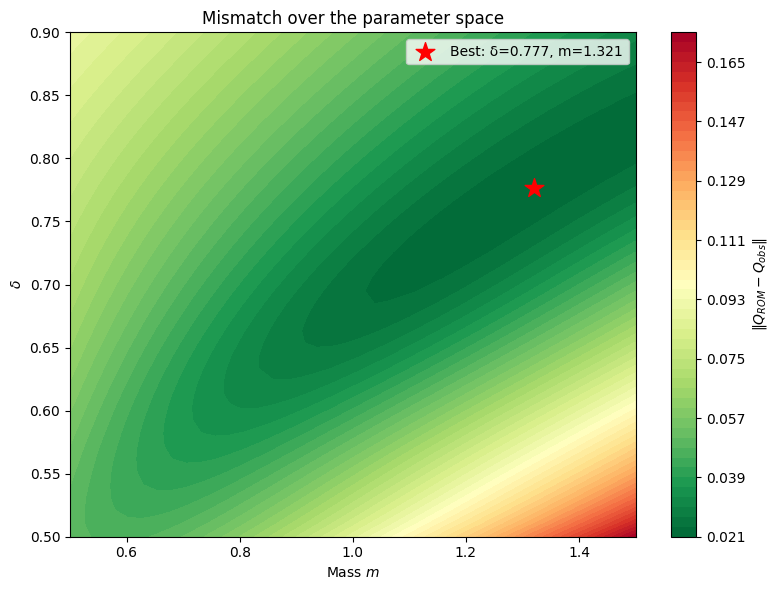

In [ ]:
# Heatmap
plt.figure(figsize=(8, 6))
plt.contourf(m_range, delta_range, mismatch_grid, levels=50, cmap='RdYlGn_r')
plt.colorbar(label=r'$\|Q_{ROM} - Q_{obs}\|$')
plt.scatter(m_opt, delta_opt, c='red', s=200, marker='*', zorder=5,
            label=f'Best: δ={delta_opt:.3f}, m={m_opt:.3f}')
plt.xlabel('Mass $m$')
plt.ylabel(r'$\delta$')
plt.title('Mismatch over the parameter space')
plt.legend()
plt.tight_layout()
plt.show()

## Observations on the Heatmap

1. The mismatch landscape shows a clear **diagonal valley** in the $(\delta, m)$ plane.
This is physically expected: a heavier pedestrian (high $m$) on a stiffer sidewalk
(high $\delta$) produces roughly the same average surface deformation as a lighter
pedestrian (low $m$) on a softer sidewalk (low $\delta$), since the two effects
**compensate each other** in $Q$. As a result, $Q$ alone is not sufficient to uniquely
identify both parameters — the inverse problem is **ill-posed** along the
$\delta$-$m$ compensation direction.


2. The best pair $(\delta^*, m^*)$ is marked with a star on the heatmap, with a relative
mismatch of $\approx 17\%$. Since the ROM test error is only $\approx 1.9\%$ and
refining the grid from $40 \times 40$ to $80 \times 80$ produces no change

   The 17% mismatch can result from:


  - Spatial accumulation error in $Q$ — at each observed instant $t_j$, $Q$ is
   computed as a discrete average over all DOFs on $\Gamma_{top}$. The ROM
   approximation error at each individual DOF accumulates across the sum, so even
   a small pointwise error $\tilde{u}_y(x_i) - u_y(x_i)$ can produce a non-negligible
   error in the scalar $Q(t_j)$. This effect repeats at each of the $q = 6$ instants
   and contributes to the total mismatch norm.



   







### How to improve the inverse problem identifiability

The current measurement setup — average vertical deformation $Q(t)$ at $q=6$ instants —
is insufficient to uniquely identify both $\delta$ and $m$, as visible from the diagonal
valley in the heatmap. Several improvements could help:

**1. Measure horizontal deformation $u_x$**

Since the external force $\mathbf{f}(t) = [0, -5m\sin(2\pi t)]^\top$ is purely vertical,
the horizontal deformation $u_x$ receives no direct contribution from the load. It arises
entirely from the **Poisson effect** — lateral expansion caused by vertical compression —
whose magnitude depends on the local stiffness. Since the two layers have different
stiffnesses (10 vs 50) and their interface is located at $y = \delta$, the horizontal
deformation pattern is **primarily sensitive to $\delta$** and largely insensitive to $m$.
Adding $u_x$ measurements would provide a signal that decouples $\delta$ from $m$.

**2. Concentrate measurements in the relaxation phase $t > 0.5$**

The force is active only for $0 \leq t \leq 0.5$ (loading phase) and zero for
$t > 0.5$ (relaxation phase). During loading, both $m$ and $\delta$ influence the
deformation simultaneously — making them hard to separate. During relaxation, the
force is zero so $m$ has no direct effect: the sidewalk recovers at a rate governed
purely by the material stiffness, i.e. by $\delta$. Concentrating more measurements
in $t > 0.5$ would provide a signal **primarily sensitive to $\delta$ alone**,
helping to decouple the two parameters.

**3. Increase the number of time instants $q$**

Currently only $q = 6$ instants are observed out of $N_t = 51$. More temporal
measurements would better resolve the deformation dynamics and reduce the ambiguity
between parameters, particularly in the relaxation phase where the $\delta$ signal
is cleaner.